<a href="https://colab.research.google.com/github/arinamartynyuk/-4-9/blob/main/%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81_%D0%9C%D0%B0%D1%80%D1%82%D0%B8%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** ______________________________  
**Група:** ______________________________  
**Дата:** ______________________________

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("x_train:", x_train.shape)
print("y_train:", y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train: (60000, 28, 28)
y_train: (60000,)
x_test: (10000, 28, 28)
y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

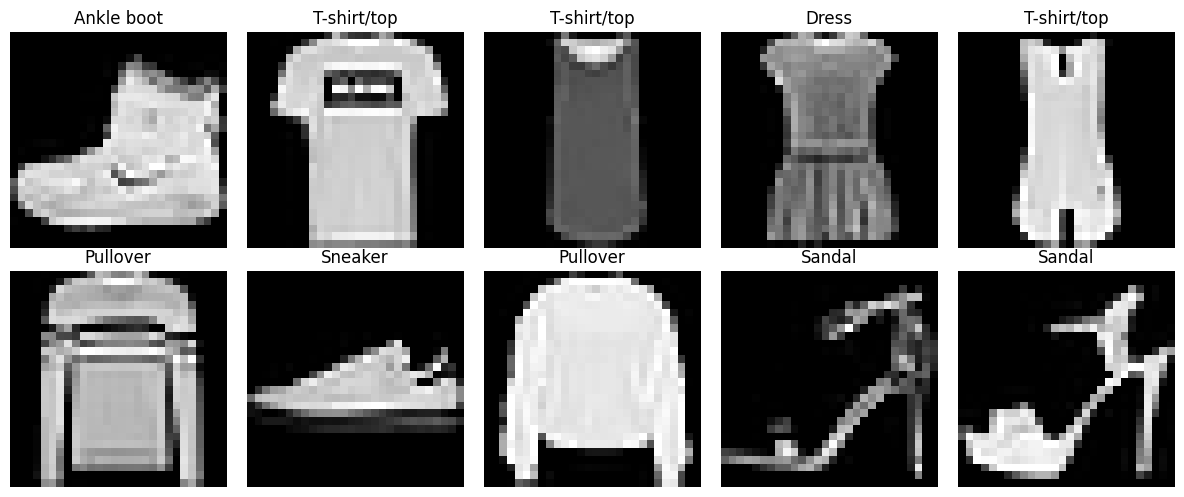

In [3]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Train range:", x_train.min(), "to", x_train.max())
print("Test range:", x_test.min(), "to", x_test.max())

Train range: 0.0 to 1.0
Test range: 0.0 to 1.0


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
model = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.25),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.20),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()

print("Вибір: 256 та 128 нейронів дають моделі достатню здатність розпізнавати ознаки.")
print("Dropout зменшує перенавчання; Adam із learning_rate=0.001 забезпечує стабільне навчання.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Вибір: 256 та 128 нейронів дають моделі достатню здатність розпізнавати ознаки.
Dropout зменшує перенавчання; Adam із learning_rate=0.001 забезпечує стабільне навчання.


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:
callbacks_1 = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)
]

history_1 = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=callbacks_1,
    verbose=1
)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7828 - loss: 0.6112 - val_accuracy: 0.8499 - val_loss: 0.4164 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8448 - loss: 0.4259 - val_accuracy: 0.8582 - val_loss: 0.3859 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8607 - loss: 0.3831 - val_accuracy: 0.8665 - val_loss: 0.3627 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.8668 - loss: 0.3611 - val_accuracy: 0.8708 - val_loss: 0.3536 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8726 - loss: 0.3403 - val_accuracy: 0.8723 - val_loss: 0.3391 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8781 - loss: 0.3306 - val_accuracy: 0.8677 - val_loss: 0.3507 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8828 - loss: 0.3139

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:
model.summary()
print("Кількість шарів:", len(model.layers))
print("Загальна кількість параметрів:", model.count_params())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)

Кількість шарів: 6
Загальна кількість параметрів: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:
model.save('fashion_mnist_model.keras')
print("Модель збережено у файл fashion_mnist_model.keras")


Модель збережено у файл fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

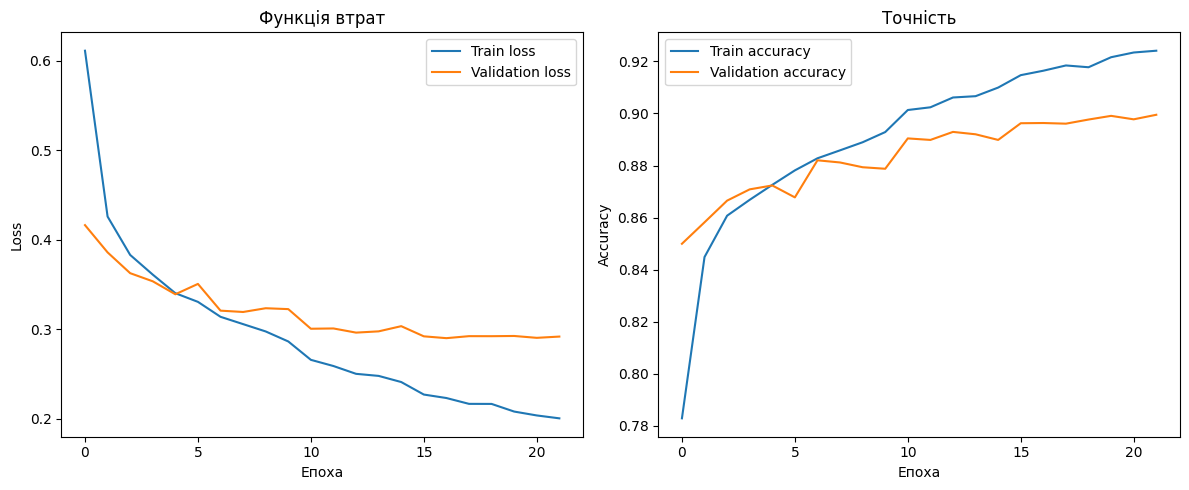

In [9]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_1.history['loss'], label='Train loss')
plt.plot(history_1.history['val_loss'], label='Validation loss')
plt.xlabel('Епоха'); plt.ylabel('Loss'); plt.title('Функція втрат')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_1.history['accuracy'], label='Train accuracy')
plt.plot(history_1.history['val_accuracy'], label='Validation accuracy')
plt.xlabel('Епоха'); plt.ylabel('Accuracy'); plt.title('Точність')
plt.legend()
plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [10]:
test_loss_1, test_acc_1 = model.evaluate(x_test, y_test, verbose=0)
pred_1 = np.argmax(model.predict(x_test, verbose=0), axis=1)

print(f"Test loss: {test_loss_1:.4f}")
print(f"Test accuracy: {test_acc_1:.4f}")
print(classification_report(y_test, pred_1, target_names=class_names))

Test loss: 0.3163
Test accuracy: 0.8902
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.84      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.79      0.82      0.81      1000
       Dress       0.88      0.90      0.89      1000
        Coat       0.80      0.81      0.81      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.73      0.69      0.71      1000
     Sneaker       0.94      0.96      0.95      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

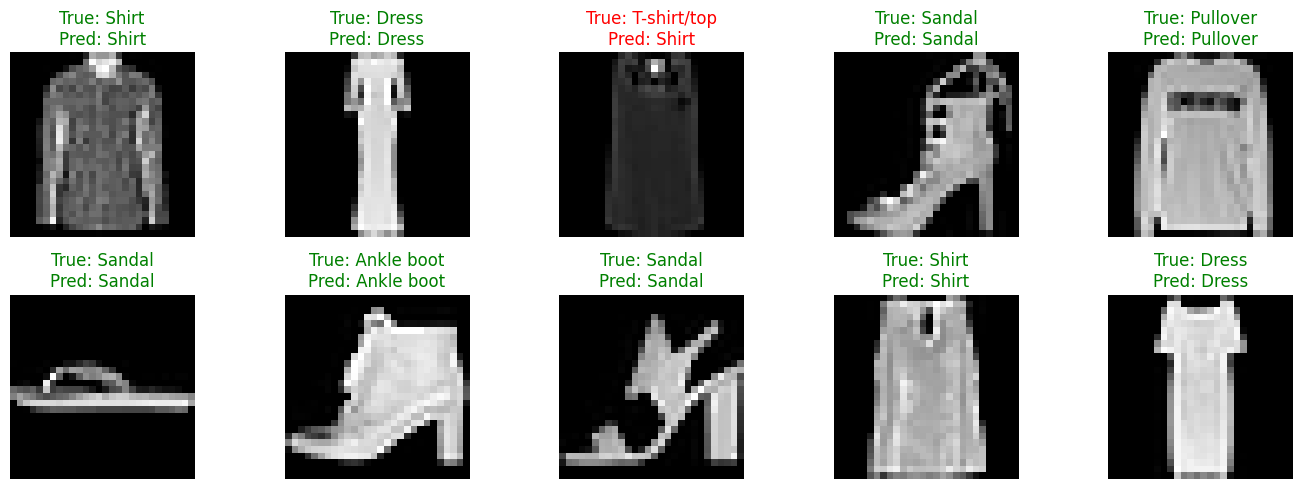

In [11]:
plt.figure(figsize=(14, 5))
indices = np.random.choice(len(x_test), 10, replace=False)
for i, idx in enumerate(indices):
    prediction = pred_1[idx]
    correct = prediction == y_test[idx]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx], cmap='gray')
    plt.title(f"True: {class_names[y_test[idx]]}\nPred: {class_names[prediction]}",
              color='green' if correct else 'red')
    plt.axis('off')
plt.tight_layout()
plt.show()

висновок:
модель оцінюється на тестовій вибірці. Якщо test_acc_1 >= 0.87, вимогу щодо точності виконано; інакше — не виконано.

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [12]:
%pip install -q keras-tuner
import keras_tuner as kt
from tensorflow.keras import regularizers
print("Keras Tuner:", kt.__version__)

Keras Tuner: 1.4.8


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [13]:
x_train_tuner, x_val_tuner, y_train_tuner, y_val_tuner = train_test_split(
    x_train, y_train, test_size=0.2, random_state=SEED, stratify=y_train
)
print("Train:", x_train_tuner.shape, y_train_tuner.shape)
print("Validation:", x_val_tuner.shape, y_val_tuner.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (48000, 28, 28) (48000,)
Validation: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [14]:
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.Flatten(input_shape=(28, 28)))

    num_hidden_layers = hp.Int('hidden_layers', min_value=1, max_value=3, step=1)
    for i in range(num_hidden_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)
        model.add(layers.Dense(
            units, activation='relu',
            kernel_regularizer=regularizers.l2(1e-4)
        ))
        dropout_rate = hp.Float(f'dropout_{i}', min_value=0.1, max_value=0.5, step=0.1)
        model.add(layers.Dropout(dropout_rate))

    model.add(layers.Dense(10, activation='softmax'))
    learning_rate = hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [15]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='keras_tuner_results',
    project_name='fashion_mnist',
    overwrite=True,
    seed=SEED
)
tuner.search_space_summary()

Search space summary
Default search space size: 4
hidden_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [16]:
callbacks_tuner = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)
]

tuner.search(
    x_train_tuner, y_train_tuner,
    epochs=20,
    batch_size=128,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=callbacks_tuner,
    verbose=1
)

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = tuner.get_best_models(num_models=1)[0]
print("Найкращі гіперпараметри:")
print(best_hp.values)
best_model.summary()

best_model = build_model(best_hp)
history_2 = best_model.fit(
    x_train_tuner, y_train_tuner,
    epochs=30,
    batch_size=128,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=callbacks_tuner,
    verbose=1
)

Trial 3 Complete [00h 01m 53s]
val_accuracy: 0.7670000195503235

Best val_accuracy So Far: 0.8607500195503235
Total elapsed time: 00h 03m 57s
Найкращі гіперпараметри:
{'hidden_layers': 3, 'units_0': 192, 'dropout_0': 0.30000000000000004, 'learning_rate': 0.01, 'units_1': 256, 'dropout_1': 0.2, 'units_2': 32, 'dropout_2': 0.1}


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 192)            │       150,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 192)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 208,682 (815.16 KB)

 Trainable params: 208,682 (815.16 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7052 - loss: 0.8832 - val_accuracy: 0.8041 - val_loss: 0.6146 - learning_rate: 0.0100
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7587 - loss: 0.7639 - val_accuracy: 0.7878 - val_loss: 0.6478 - learning_rate: 0.0100
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7730 - loss: 0.7400 - val_accuracy: 0.8321 - val_loss: 0.5974 - learning_rate: 0.0100
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 17ms/step - accuracy: 0.7686 - loss: 0.7518 - val_accuracy: 0.8243 - val_loss: 0.6249 - learning_rate: 0.0100
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.7660 - loss: 0.7585 - val_accuracy: 0.8143 - val_loss: 0.6459 - learning_rate: 0.0100
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7973 - loss: 0.6560 - val_accuracy: 0.8360 - val_loss: 0.5474 - learning_rate: 0.0050
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8038 - loss: 0.622

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

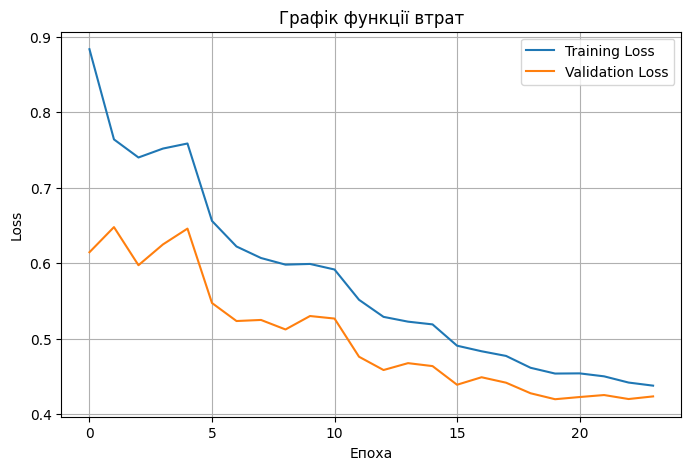

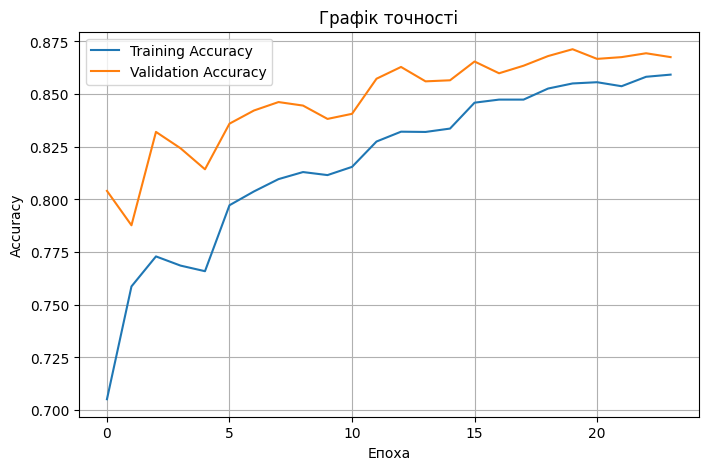

In [20]:
import matplotlib.pyplot as plt

# Графік функції втрат
plt.figure(figsize=(8, 5))
plt.plot(history_2.history['loss'], label='Training Loss')
plt.plot(history_2.history['val_loss'], label='Validation Loss')
plt.title('Графік функції втрат')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Графік точності
plt.figure(figsize=(8, 5))
plt.plot(history_2.history['accuracy'], label='Training Accuracy')
plt.plot(history_2.history['val_accuracy'], label='Validation Accuracy')
plt.title('Графік точності')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

## Висновки. Порівняння моделей

У першому завданні було побудовано нейронну мережу з двома прихованими шарами, які містили 256 та 128 нейронів відповідно. Швидкість навчання становила 0,001. Точність моделі на тестовій вибірці склала 0,8902, а втрати — 0,3163. Навчання тривало 22 епохи.

Таким чином, у завданні 1 було досягнуто точності 0,8902, що є вище заданого порогу 0,87.

Після автоматизованого налаштування гіперпараметрів за допомогою Keras Tuner було отримано іншу конфігурацію нейронної мережі. Під час оптимізації підбиралися кількість прихованих шарів, кількість нейронів та швидкість навчання. Результати оптимізованої моделі порівнювалися з початковою моделлю за точністю та втратами на тестовій вибірці. Ефективність оптимізації визначається отриманою тестовою точністю, яка може бути як вищою, так і нижчою за результат першої моделі.

Найкращими гіперпараметрами вважаються ті, які забезпечили найкращий результат під час пошуку Keras Tuner. Результати можуть відрізнятися між запусками через випадкову ініціалізацію ваг, особливості навчання нейронної мережі та вибрані гіперпараметри.

Найскладніше класифікувати класи Fashion MNIST, які мають схожий зовнішній вигляд, наприклад футболки, сорочки, светри та пальта. Через схожість форм і деталей нейронна мережа може помилково визначати їхні категорії.

### Власні висновки

У ході лабораторної роботи було створено, навчено та оцінено нейронну мережу для класифікації зображень набору даних Fashion MNIST. Було використано бібліотеку Keras, виконано нормалізацію даних, навчання моделі, оцінювання її точності та втрат, а також автоматизований підбір гіперпараметрів за допомогою Keras Tuner.

Початкова модель досягла точності 0,8902, що підтверджує її достатню ефективність для виконання поставленого завдання. Автоматизований підбір гіперпараметрів дозволив дослідити різні конфігурації нейронної мережі та порівняти їхні результати.

Під час виконання лабораторної роботи було отримано практичні навички роботи з нейронними мережами, їх навчання, оцінювання та оптимізації.